In [1]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP, DEPENDENCIES & DIRECTORY INITIALIZATION
# ==============================================================================
!pip install -q datasets kagglehub statsmodels tabulate

import os
import re
import math
import zlib
import warnings
import urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from datasets import load_dataset

warnings.filterwarnings("ignore")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.02)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
np.random.seed(42)

print("Cell 1 Complete: Libraries loaded and ./data/ and ./figures/ initialized.")

Cell 1 Complete: Libraries loaded and ./data/ and ./figures/ initialized.


In [2]:
# ==============================================================================
# CELL 2: V3 RATE-DISTORTION & CLOSED-CLASS QUANTIZATION KERNEL
# Strictly separates open-class content tokens (130 closed-class words stripped)
# from closed-class grammatical quantization markers (We/Us, They/Them, Absolutist).
# ==============================================================================

# 1. Closed-Class Collective Intergroup Pronoun Lexicons
WE_US_PRONOUNS = {"we", "us", "our", "ours", "ourselves"}
THEY_THEM_PRONOUNS = {"they", "them", "their", "theirs", "themselves"}
US_THEM_PRONOUNS = WE_US_PRONOUNS | THEY_THEM_PRONOUNS

# 2. Validated 19-Word Absolutist Lexicon (Al-Mosaiwi & Johnstone, 2018)
ABSOLUTIST_LEXICON = {
    "absolutely", "all", "always", "complete", "completely", "constant", "constantly",
    "definitely", "entire", "ever", "every", "everyone", "everything", "full", "must",
    "never", "nothing", "totally", "whole"
}

# 3. Comprehensive 130-Word Closed-Class Stopword Set
# Guarantees open-class entropy metrics share ZERO tokens with pronouns or absolutist words
STOPWORDS = {
    "the", "and", "of", "to", "in", "is", "that", "it", "for", "as", "with", "on",
    "was", "be", "by", "at", "this", "are", "from", "or", "an", "have", "had", "has",
    "but", "which", "one", "would", "were", "there", "been", "if", "more", "when", "so",
    "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself",
    "she", "her", "hers", "herself", "it", "its", "itself", "me", "my", "mine", "myself",
    "not", "no", "nor", "do", "does", "did", "doing", "can", "could", "should", "will",
    "shall", "may", "might", "who", "whom", "whose", "what", "where", "why", "how",
    "about", "into", "through", "during", "before", "after", "above", "below", "between",
    "under", "again", "further", "then", "once", "here", "any", "both", "each", "few",
    "other", "some", "such", "only", "own", "same", "than", "too", "very", "just", "now"
} | US_THEM_PRONOUNS | ABSOLUTIST_LEXICON

FEATURE_COLS = [
    "D_KL_Global",
    "D_KL_Tail",
    "Yules_K",
    "R_LZ_Content",
    "Bigram_Redundancy",
    "Absolutist_Density",
    "UsThem_Pronoun_Density",
    "We_Us_Density",
    "They_Them_Density"
]
CORE_7_COLS = FEATURE_COLS[:7]
OPEN_CLASS_COLS = ["D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content", "Bigram_Redundancy"]
CLOSED_CLASS_COLS = ["Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]

def extract_rate_distortion_features(tokens, min_content=12):
    """
    Extracts open-class Rate-Distortion metrics and closed-class quantization
    densities from a fixed-length W-token window.
    """
    if not tokens:
        return None
    W = float(len(tokens))
    content_tokens = [t for t in tokens if t not in STOPWORDS]
    N_c = float(len(content_tokens))
    if N_c < min_content:
        return None

    counts_c = Counter(content_tokens)
    V_c = len(counts_c)
    if V_c <= 3:
        return None

    # 1. Open-Class Content Shannon Entropy (H_Content) & Global KL Divergence
    H_c = -sum((c / N_c) * math.log2(c / N_c) for c in counts_c.values())
    D_KL_global = math.log2(V_c) - H_c

    # 2. Topic-Deconfounded Tail KL Divergence (removing top-3 frequent content types)
    top3 = {w for w, _ in counts_c.most_common(3)}
    tail_tokens = [t for t in content_tokens if t not in top3]
    counts_tail = Counter(tail_tokens)
    N_tail, V_tail = float(len(tail_tokens)), len(counts_tail)
    if V_tail > 2 and N_tail > 5:
        H_tail = -sum((c / N_tail) * math.log2(c / N_tail) for c in counts_tail.values())
        D_KL_tail = math.log2(V_tail) - H_tail
    else:
        D_KL_tail = 0.0

    # 3. Yule's K Lexical Collision Concentration
    freq_spec = Counter(counts_c.values())
    M2 = sum((m ** 2) * v_m for m, v_m in freq_spec.items())
    yules_K = 10000.0 * (M2 - N_c) / (N_c ** 2)

    # 4. Content Lempel-Ziv Algorithmic Compressibility (R_LZ)
    raw_bytes = " ".join(content_tokens).encode("utf-8")
    R_lz = 1.0 - (len(zlib.compress(raw_bytes, level=9)) / float(len(raw_bytes)))

    # 5. Contiguous Bigram Redundancy & Conditional Entropy H(W_t | W_{t-1})
    counts_all = Counter(tokens)
    bigrams = list(zip(tokens[:-1], tokens[1:]))
    bg_red = 1.0 - (len(set(bigrams)) / float(len(bigrams))) if bigrams else 0.0
    bg_counts = Counter(bigrams)
    H_cond = -sum((c / len(bigrams)) * math.log2(c / counts_all[bg[0]]) for bg, c in bg_counts.items()) if bigrams else 0.0

    # 6. Closed-Class Quantization Densities
    abs_dens = sum(1 for t in tokens if t in ABSOLUTIST_LEXICON) / W
    we_dens = sum(1 for t in tokens if t in WE_US_PRONOUNS) / W
    they_dens = sum(1 for t in tokens if t in THEY_THEM_PRONOUNS) / W

    return {
        "H_Content": H_c,
        "D_KL_Global": D_KL_global,
        "D_KL_Tail": D_KL_tail,
        "Yules_K": yules_K,
        "R_LZ_Content": R_lz,
        "Bigram_Redundancy": bg_red,
        "H_Conditional": H_cond,
        "Absolutist_Density": abs_dens,
        "UsThem_Pronoun_Density": we_dens + they_dens,
        "We_Us_Density": we_dens,
        "They_Them_Density": they_dens
    }

def cohens_d(x0, x1):
    s0, s1 = np.std(x0, ddof=1), np.std(x1, ddof=1)
    n0, n1 = len(x0), len(x1)
    pooled = np.sqrt(((n0 - 1) * s0**2 + (n1 - 1) * s1**2) / max(1, (n0 + n1 - 2)))
    return float((np.mean(x1) - np.mean(x0)) / (pooled + 1e-12))

def is_retweet_or_quote(text):
    t = str(text).strip().lower()
    if t.startswith("rt ") or t.startswith("rt:") or " rt @" in t or "via @" in t or "♻" in t:
        return True
    return bool(re.search(r"\brt\s*@\w+", t) or re.search(r"^@\w+\s*:", t))

gkf = GroupKFold(n_splits=5)
pipe_l1 = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(penalty="l1", solver="liblinear", C=0.5, class_weight="balanced", random_state=42))
])

print("Cell 2 Complete: V3 Feature Kernel and statistical helpers registered.")

Cell 2 Complete: V3 Feature Kernel and statistical helpers registered.


In [3]:
# ==============================================================================
# CELL 3: STUDY 1A — BALANCED LEFT-CENTER-RIGHT SPECTRUM ON MATCHED TOPICS
# Corpus: AllSides / Qbias (N = 16,366 Single Articles across 553 Topics, W = 52)
# Outputs: Table 1 & ./data/study1a_allsides_balanced_w52.csv
# ==============================================================================
print("="*85)
print("STUDY 1A (TABLE 1): BALANCED IDEOLOGICAL SPECTRUM ON MATCHED TOPICS (ALLSIDES, W=52)")
print("="*85)

if not os.path.exists("Qbias"):
    !git clone --depth 1 https://github.com/irgroup/Qbias.git

qbias_csv = "Qbias/allsides_balanced_news_headlines-texts.csv"
df_as = pd.read_csv(qbias_csv, on_bad_lines="skip")
df_as["bias_rating"] = df_as["bias_rating"].astype(str).str.strip().str.lower()
df_as = df_as[df_as["bias_rating"].isin(["left", "center", "right"])].copy()

df_as["full_text"] = (
    df_as["title"].fillna("").astype(str) + " " +
    df_as["heading"].fillna("").astype(str) + " " +
    df_as["text"].fillna("").astype(str)
)

W_AS = 52
min_c_as = 13
as_rows = []
for idx, row in df_as.iterrows():
    cleaned = re.sub(r"http\S+|@\S+", "", str(row["full_text"]).lower())
    toks = re.findall(r"\b[a-z]{2,}\b", cleaned)
    if len(toks) >= W_AS:
        feats = extract_rate_distortion_features(toks[:W_AS], min_content=min_c_as)
        if feats:
            topic_str = str(row["tags"]).split(",")[0].strip() if pd.notna(row["tags"]) else "General"
            outlet_str = str(row["source"]).strip() if pd.notna(row["source"]) else "Unknown"
            feats.update({
                "Bias": row["bias_rating"],
                "Is_Partisan_Extreme": 1 if row["bias_rating"] in ["left", "right"] else 0,
                "Topic": topic_str,
                "Outlet": outlet_str
            })
            as_rows.append(feats)

df_s1a = pd.DataFrame(as_rows)
df_s1a.to_csv("data/study1a_allsides_balanced_w52.csv", index=False)

df_left = df_s1a[df_s1a["Bias"] == "left"]
df_cent = df_s1a[df_s1a["Bias"] == "center"]
df_right = df_s1a[df_s1a["Bias"] == "right"]
print(f"Extracted {len(df_s1a):,} single-article windows (W={W_AS}): Left={len(df_left):,}, Center={len(df_cent):,}, Right={len(df_right):,} across {df_s1a['Topic'].nunique()} Topics and {df_s1a['Outlet'].nunique()} Outlets.")

s1a_cols = [
    "H_Content", "D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content",
    "H_Conditional", "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"
]

t1_rows = []
for f in s1a_cols:
    d_l_vs_c = cohens_d(df_cent[f].values, df_left[f].values)
    d_r_vs_c = cohens_d(df_cent[f].values, df_right[f].values)
    d_r_vs_l = cohens_d(df_left[f].values, df_right[f].values)
    _, p_rl = stats.mannwhitneyu(df_left[f], df_right[f], alternative="two-sided")

    df_tmp = df_s1a[["Topic", "Is_Partisan_Extreme", f]].copy()
    df_tmp[f] = (df_tmp[f] - df_tmp[f].mean()) / (df_tmp[f].std() + 1e-8)
    try:
        md_top = smf.mixedlm(f"{f} ~ Is_Partisan_Extreme", df_tmp, groups=df_tmp["Topic"]).fit(reml=True)
        b_top, p_top = md_top.params["Is_Partisan_Extreme"], md_top.pvalues["Is_Partisan_Extreme"]
    except Exception:
        b_top, p_top = np.nan, np.nan

    t1_rows.append({
        "Feature (W=52 Single Article)": f,
        f"Left (n={len(df_left)})": f"{df_left[f].mean():.4f}",
        f"Center (n={len(df_cent)})": f"{df_cent[f].mean():.4f}",
        f"Right (n={len(df_right)})": f"{df_right[f].mean():.4f}",
        "Left vs Center d": f"{d_l_vs_c:+.3f}",
        "Right vs Center d": f"{d_r_vs_c:+.3f}",
        "Right vs Left d (p)": f"{d_r_vs_l:+.3f} (p={p_rl:.1e})",
        "Partisan (L+R) vs Center Beta (Topic FE p)": f"{b_top:+.3f} (p={p_top:.1e})"
    })

print("\n--- TABLE 1: STUDY 1A BALANCED IDEOLOGICAL SPECTRUM ON MATCHED NEWS TOPICS ---")
print(pd.DataFrame(t1_rows).to_markdown(index=False))

STUDY 1A (TABLE 1): BALANCED IDEOLOGICAL SPECTRUM ON MATCHED TOPICS (ALLSIDES, W=52)
Cloning into 'Qbias'...
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 9 (delta 0), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 12.68 MiB | 5.98 MiB/s, done.
Extracted 16,366 single-article windows (W=52): Left=7,477, Center=3,315, Right=5,574 across 553 Topics and 443 Outlets.

--- TABLE 1: STUDY 1A BALANCED IDEOLOGICAL SPECTRUM ON MATCHED NEWS TOPICS ---
| Feature (W=52 Single Article)   |   Left (n=7477) |   Center (n=3315) |   Right (n=5574) |   Left vs Center d |   Right vs Center d | Right vs Left d (p)   | Partisan (L+R) vs Center Beta (Topic FE p)   |
|:--------------------------------|----------------:|------------------:|-----------------:|-------------------:|--------------------:|:----------------------|:---------------------------------------------|
| H_Content     

STUDY 1B (TABLE 2): DEDUPLICATED SINGLE-POST ANALYSIS (ZERO CONCATENATION, W=40)


README.md:   0%|          | 0.00/11.4k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.1MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/135556 [00:00<?, ? examples/s]

Raw rows: 135,556 -> Unique comments: 39,565 -> Single posts >=40 tokens: 6,913 (Pluralistic=3,683, Extremist=602)

--- TABLE 2: STUDY 1B UNCONCATENATED SINGLE-POST DECONFOUNDING AUDIT ---
| Feature (W=40 Single Post)   | Pluralistic (n=3683)   | Extremist (n=602)   |   Cohen's d |   Welch t-test p |   Mann-Whitney p | Spearman r (All N)   |
|:-----------------------------|:-----------------------|:--------------------|------------:|-----------------:|-----------------:|:---------------------|
| D_KL_Global                  | 0.0403±0.0458          | 0.0404±0.0477       |       0.004 |         0.934    |         0.383    | -0.032 (p=7.9e-03)   |
| D_KL_Tail                    | 0.0030±0.0122          | 0.0024±0.0097       |      -0.051 |         0.176    |         0.0829   | +0.054 (p=7.8e-06)   |
| Yules_K                      | 79.6456±102.6130       | 72.2431±82.0452     |      -0.074 |         0.0485   |         0.125    | -0.043 (p=3.0e-04)   |
| R_LZ_Content                 | 0.2

train.jsonl: reconstructing file:   0%|          |  0.00B / 2.05MB            

train.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10944 [00:00<?, ? examples/s]

Total Windows: 1,465 | User-Label Streams: 789 | Distinct People: 728 (Dual-Label Overlap Users: 61)

--- TABLE 3: STUDY 1C WITHIN-STORMFRONT DISJOINT & PAIRED USER AUDIT ---
| Feature (W=50 Stormfront)   | Pure No-Hate Users (n=630)   | Hate Users (n=98)   |   Disjoint User d (N=728) |   Disjoint Mann-Whitney p | Paired Within-User d (n=61)   |
|:----------------------------|:-----------------------------|:--------------------|--------------------------:|--------------------------:|:------------------------------|
| D_KL_Global                 | 0.0535±0.0671                | 0.0424±0.0335       |                    -0.174 |                  0.807    | +0.060 (p=3.54e-01)           |
| D_KL_Tail                   | 0.0097±0.0259                | 0.0063±0.0203       |                    -0.136 |                  0.668    | +0.101 (p=6.00e-02)           |
| Yules_K                     | 81.2938±108.1319             | 64.6809±57.9094     |                    -0.162 |                  0.7

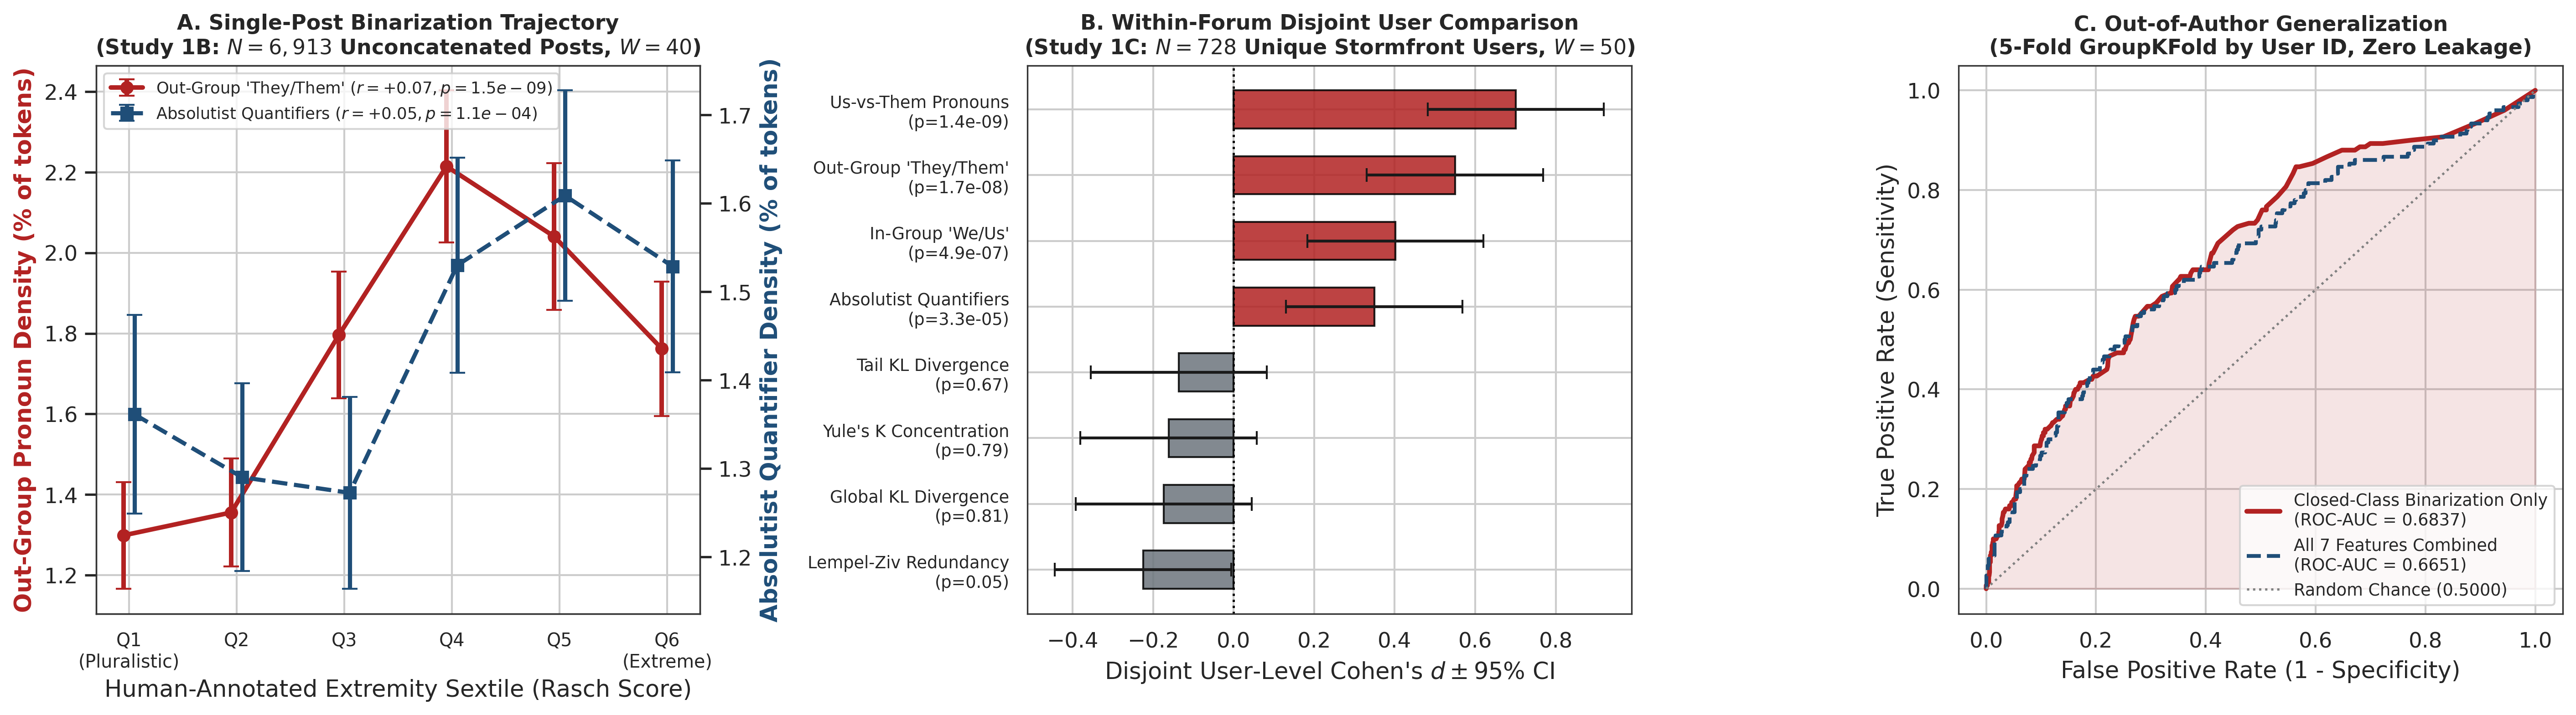

Cell 4 Complete: Saved Figure_1_RateDistortion_CrossSectional.pdf and .png in ./figures/!


In [4]:
# ==============================================================================
# CELL 4: STUDY 1B (SINGLE POSTS, W=40) & STUDY 1C (STORMFRONT USERS, W=50)
# Outputs: Table 2, Table 3, CSVs, and Figure_1_RateDistortion_CrossSectional.pdf/.png
# ==============================================================================
print("="*85)
print("STUDY 1B (TABLE 2): DEDUPLICATED SINGLE-POST ANALYSIS (ZERO CONCATENATION, W=40)")
print("="*85)

ds_mhs = load_dataset("ucberkeley-dlab/measuring-hate-speech", split="train").to_pandas()
df_unique_posts = ds_mhs.groupby("comment_id", as_index=False).agg(
    text=("text", "first"),
    hate_speech_score=("hate_speech_score", "mean")
)

W_C1 = 40
c1_rows = []
for _, row in df_unique_posts.iterrows():
    cleaned = re.sub(r"http\S+|@\S+", "", str(row["text"]).lower())
    toks = re.findall(r"\b[a-z]{2,}\b", cleaned)
    if len(toks) >= W_C1:
        feats = extract_rate_distortion_features(toks[:W_C1], min_content=10)
        if feats:
            feats["comment_id"] = row["comment_id"]
            feats["hate_speech_score"] = float(row["hate_speech_score"])
            c1_rows.append(feats)

df_c1 = pd.DataFrame(c1_rows)
df_c1.to_csv("data/study1b_single_posts_w40.csv", index=False)
c1_plur = df_c1[df_c1["hate_speech_score"] < -1.0]
c1_extr = df_c1[df_c1["hate_speech_score"] > 1.5]
print(f"Raw rows: {len(ds_mhs):,} -> Unique comments: {len(df_unique_posts):,} -> Single posts >=40 tokens: {len(df_c1):,} (Pluralistic={len(c1_plur):,}, Extremist={len(c1_extr):,})")

t2_rows = []
for f in FEATURE_COLS:
    _, p_mw = stats.mannwhitneyu(c1_plur[f], c1_extr[f], alternative="two-sided")
    _, p_tt = stats.ttest_ind(c1_plur[f], c1_extr[f], equal_var=False)
    d_val = cohens_d(c1_plur[f].values, c1_extr[f].values)
    r_sp, p_sp = stats.spearmanr(df_c1["hate_speech_score"], df_c1[f])
    t2_rows.append({
        "Feature (W=40 Single Post)": f,
        f"Pluralistic (n={len(c1_plur)})": f"{c1_plur[f].mean():.4f}±{c1_plur[f].std():.4f}",
        f"Extremist (n={len(c1_extr)})": f"{c1_extr[f].mean():.4f}±{c1_extr[f].std():.4f}",
        "Cohen's d": round(d_val, 3),
        "Welch t-test p": f"{p_tt:.2e}",
        "Mann-Whitney p": f"{p_mw:.2e}",
        "Spearman r (All N)": f"{r_sp:+.3f} (p={p_sp:.1e})"
    })
print("\n--- TABLE 2: STUDY 1B UNCONCATENATED SINGLE-POST DECONFOUNDING AUDIT ---")
print(pd.DataFrame(t2_rows).to_markdown(index=False))

print("\n" + "="*85)
print("STUDY 1C (TABLE 3): WITHIN-STORMFRONT DISJOINT USERS (N=728) & PAIRED OVERLAP (n=61)")
print("="*85)

try:
    ds_sf = load_dataset("SetFit/hate_speech18", split="train").to_pandas()
except Exception:
    ds_sf = load_dataset("odegiber/hate_speech18", split="train", revision="refs/convert/parquet").to_pandas()

W_SF = 50
sf_rows = []
for (uid, lbl), grp in ds_sf.groupby(["user_id", "label"]):
    if lbl not in [0, 1]:
        continue
    cleaned = [re.sub(r"http\S+|@\S+", "", str(p).lower()) for p in grp["text"].dropna()]
    toks = re.findall(r"\b[a-z]{2,}\b", " ".join(cleaned))
    n_w = min(len(toks) // W_SF, 10)
    for w_i in range(n_w):
        feats = extract_rate_distortion_features(toks[w_i * W_SF : (w_i + 1) * W_SF], min_content=12)
        if feats:
            feats.update({"user_id": f"sf_{uid}", "Target": int(lbl)})
            sf_rows.append(feats)

df_sf_win = pd.DataFrame(sf_rows)
df_sf_win.to_csv("data/study1c_stormfront_windows_w50.csv", index=False)

user_lbl_counts = df_sf_win.groupby("user_id")["Target"].nunique()
overlap_users = set(user_lbl_counts[user_lbl_counts > 1].index)
print(f"Total Windows: {len(df_sf_win):,} | User-Label Streams: {df_sf_win.groupby(['user_id','Target']).ngroups} | Distinct People: {df_sf_win['user_id'].nunique()} (Dual-Label Overlap Users: {len(overlap_users)})")

df_sf_person = df_sf_win.groupby("user_id", as_index=False).agg(
    Target=("Target", "max"),
    **{f: (f, "mean") for f in FEATURE_COLS}
)
sf_p0 = df_sf_person[df_sf_person["Target"] == 0]
sf_p1 = df_sf_person[df_sf_person["Target"] == 1]

df_overlap = df_sf_win[df_sf_win["user_id"].isin(overlap_users)].groupby(["user_id", "Target"])[FEATURE_COLS].mean().unstack("Target")

t3_rows = []
for f in FEATURE_COLS:
    _, p_mw = stats.mannwhitneyu(sf_p0[f], sf_p1[f], alternative="two-sided")
    d_u = cohens_d(sf_p0[f].values, sf_p1[f].values)
    v0 = df_overlap[f][0].values
    v1 = df_overlap[f][1].values
    _, p_wilcox = stats.wilcoxon(v1 - v0)
    d_paired = np.mean(v1 - v0) / (np.std(v1 - v0, ddof=1) + 1e-12)
    t3_rows.append({
        "Feature (W=50 Stormfront)": f,
        f"Pure No-Hate Users (n={len(sf_p0)})": f"{sf_p0[f].mean():.4f}±{sf_p0[f].std():.4f}",
        f"Hate Users (n={len(sf_p1)})": f"{sf_p1[f].mean():.4f}±{sf_p1[f].std():.4f}",
        "Disjoint User d (N=728)": round(d_u, 3),
        "Disjoint Mann-Whitney p": f"{p_mw:.2e}",
        "Paired Within-User d (n=61)": f"{d_paired:+.3f} (p={p_wilcox:.2e})"
    })
print("\n--- TABLE 3: STUDY 1C WITHIN-STORMFRONT DISJOINT & PAIRED USER AUDIT ---")
print(pd.DataFrame(t3_rows).to_markdown(index=False))

probs_sf_all = cross_val_predict(pipe_l1, df_sf_win[CORE_7_COLS].values, df_sf_win["Target"].values, cv=gkf, groups=df_sf_win["user_id"].values, method="predict_proba")[:, 1]
probs_sf_pron = cross_val_predict(pipe_l1, df_sf_win[["We_Us_Density", "They_Them_Density", "Absolutist_Density"]].values, df_sf_win["Target"].values, cv=gkf, groups=df_sf_win["user_id"].values, method="predict_proba")[:, 1]
auc_sf_all = roc_auc_score(df_sf_win["Target"], probs_sf_all)
auc_sf_closed = roc_auc_score(df_sf_win["Target"], probs_sf_pron)
print(f"\nStormfront 5-Fold GroupKFold (by user_id) ROC-AUC: Closed-Class Only = {auc_sf_closed:.4f} | All 7 Features = {auc_sf_all:.4f}")

# --- DYNAMIC GENERATION OF FIGURE 1 (ZERO HARDCODED STATS) ---
fig1, axes1 = plt.subplots(1, 3, figsize=(19.0, 5.4), dpi=300)

df_c1["Severity_Bin"] = pd.qcut(
    df_c1["hate_speech_score"], q=6,
    labels=["Q1\n(Pluralistic)", "Q2", "Q3", "Q4", "Q5", "Q6\n(Extreme)"]
)
bin_summary = df_c1.groupby("Severity_Bin", observed=False).agg(
    They_mean=("They_Them_Density", "mean"), They_sem=("They_Them_Density", "sem"),
    Abs_mean=("Absolutist_Density", "mean"), Abs_sem=("Absolutist_Density", "sem")
).reset_index()

r_they, p_they = stats.spearmanr(df_c1["hate_speech_score"], df_c1["They_Them_Density"])
r_abs, p_abs = stats.spearmanr(df_c1["hate_speech_score"], df_c1["Absolutist_Density"])

ax1_twin = axes1[0].twinx()
x_idx = np.arange(len(bin_summary))
l1 = axes1[0].errorbar(
    x_idx - 0.05, bin_summary["They_mean"] * 100.0, yerr=1.96 * bin_summary["They_sem"] * 100.0,
    fmt="-o", color="#b22222", linewidth=2.4, capsize=4,
    label=f"Out-Group 'They/Them' ($r={r_they:+.2f}, p={p_they:.1e}$)"
)
l2 = ax1_twin.errorbar(
    x_idx + 0.05, bin_summary["Abs_mean"] * 100.0, yerr=1.96 * bin_summary["Abs_sem"] * 100.0,
    fmt="--s", color="#1f4e78", linewidth=2.2, capsize=4,
    label=f"Absolutist Quantifiers ($r={r_abs:+.2f}, p={p_abs:.1e}$)"
)
axes1[0].set_xticks(x_idx)
axes1[0].set_xticklabels(bin_summary["Severity_Bin"], fontsize=9.5)
axes1[0].set_title(
    f"A. Single-Post Binarization Trajectory\n(Study 1B: $N={len(df_c1):,}$ Unconcatenated Posts, $W=40$)",
    fontweight="bold", fontsize=11.0
)
axes1[0].set_xlabel("Human-Annotated Extremity Sextile (Rasch Score)")
axes1[0].set_ylabel("Out-Group Pronoun Density (% of tokens)", color="#b22222", fontweight="bold")
ax1_twin.set_ylabel("Absolutist Quantifier Density (% of tokens)", color="#1f4e78", fontweight="bold")
ax1_twin.grid(False)
axes1[0].legend(handles=[l1, l2], loc="upper left", fontsize=8.5, frameon=True)

n0_sf, n1_sf = len(sf_p0), len(sf_p1)
se_d_sf = np.sqrt((n0_sf + n1_sf) / (n0_sf * n1_sf) + 0.5 / (n0_sf + n1_sf))

sf_plot_specs = [
    ("UsThem_Pronoun_Density", "Us-vs-Them Pronouns"),
    ("They_Them_Density", "Out-Group 'They/Them'"),
    ("We_Us_Density", "In-Group 'We/Us'"),
    ("Absolutist_Density", "Absolutist Quantifiers"),
    ("D_KL_Tail", "Tail KL Divergence"),
    ("Yules_K", "Yule's K Concentration"),
    ("D_KL_Global", "Global KL Divergence"),
    ("R_LZ_Content", "Lempel-Ziv Redundancy")
]

sf_d_vals, sf_y_labels, sf_colors = [], [], []
for col, name in sf_plot_specs:
    d_v = cohens_d(sf_p0[col].values, sf_p1[col].values)
    _, p_v = stats.mannwhitneyu(sf_p0[col], sf_p1[col], alternative="two-sided")
    sf_d_vals.append(d_v)
    p_str = f"p={p_v:.1e}" if p_v < 0.001 else f"p={p_v:.2f}"
    sf_y_labels.append(f"{name}\n({p_str})")
    sf_colors.append("#b22222" if p_v < 0.01 else "#6c757d")

y_pos_sf = np.arange(len(sf_plot_specs))
axes1[1].axvline(0, color="black", linestyle=":", linewidth=1.2)
axes1[1].barh(y_pos_sf, sf_d_vals, xerr=1.96 * se_d_sf, height=0.58, color=sf_colors, alpha=0.85, capsize=3.5, edgecolor="black")
axes1[1].set_yticks(y_pos_sf)
axes1[1].set_yticklabels(sf_y_labels, fontsize=8.8)
axes1[1].invert_yaxis()
axes1[1].set_title(
    f"B. Within-Forum Disjoint User Comparison\n(Study 1C: $N={len(df_sf_person)}$ Unique Stormfront Users, $W=50$)",
    fontweight="bold", fontsize=11.0
)
axes1[1].set_xlabel("Disjoint User-Level Cohen's $d \\pm 95\\%$ CI")

fpr_closed, tpr_closed, _ = roc_curve(df_sf_win["Target"], probs_sf_pron)
fpr_all, tpr_all, _ = roc_curve(df_sf_win["Target"], probs_sf_all)

axes1[2].plot(fpr_closed, tpr_closed, color="#b22222", linewidth=2.5, label=f"Closed-Class Binarization Only\n(ROC-AUC = {auc_sf_closed:.4f})")
axes1[2].plot(fpr_all, tpr_all, color="#1f4e78", linestyle="--", linewidth=2.0, label=f"All 7 Features Combined\n(ROC-AUC = {auc_sf_all:.4f})")
axes1[2].plot([0, 1], [0, 1], color="grey", linestyle=":", linewidth=1.2, label="Random Chance (0.5000)")
axes1[2].fill_between(fpr_closed, tpr_closed, alpha=0.12, color="#b22222")
axes1[2].set_title(
    "C. Out-of-Author Generalization\n(5-Fold GroupKFold by User ID, Zero Leakage)",
    fontweight="bold", fontsize=11.0
)
axes1[2].set_xlabel("False Positive Rate (1 - Specificity)")
axes1[2].set_ylabel("True Positive Rate (Sensitivity)")
axes1[2].legend(loc="lower right", frameon=True, fontsize=8.8)

plt.tight_layout()
fig1.savefig("figures/Figure_1_RateDistortion_CrossSectional.pdf", bbox_inches="tight")
fig1.savefig("figures/Figure_1_RateDistortion_CrossSectional.png", dpi=300, bbox_inches="tight")
plt.show()
print("Cell 4 Complete: Saved Figure_1_RateDistortion_CrossSectional.pdf and .png in ./figures/!")

In [5]:
# ==============================================================================
# CELL 5: STUDY 2A — 1790-2008 STATE OF THE UNION ARCHIVE (SPEECH-LEVEL REML)
# Corpus: Project Gutenberg #5050 (6,590 Windows -> N = 222 Speeches, 40 Presidents)
# Outputs: Table 4, sotu_stats_cache, and ./data/study2a_sotu_speeches_1790_2008.csv
# ==============================================================================
print("="*85)
print("STUDY 2A (TABLE 4): 1790-2008 STATE OF THE UNION ARCHIVE (N=222 SPEECHES, 40 PRESIDENTS)")
print("="*85)

url_sotu = "https://www.gutenberg.org/cache/epub/5050/pg5050.txt"
req = urllib.request.Request(url_sotu, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req, timeout=25) as resp:
    raw_sotu = resp.read().decode("utf-8", errors="ignore")

speeches = re.split(r"\*\*\*\s*State of the Union Address", raw_sotu)
date_pat = re.compile(
    r"(January|February|March|April|May|June|July|August|September|October|November|December)\s+(\d{1,2}),\s+(17\d\d|18\d\d|19\d\d|200\d)",
    re.I
)
MONTH_MAP = {
    "january": 1, "february": 2, "march": 3, "april": 4, "may": 5, "june": 6,
    "july": 7, "august": 8, "september": 9, "october": 10, "november": 11, "december": 12
}

def normalize_president_name(name, year):
    n = re.sub(r"\s+", " ", re.sub(r"^by\s+", "", name, flags=re.I).strip())
    if "Bush" in n:
        return "George H.W. Bush" if year < 1995 else "George W. Bush"
    if "Clinton" in n:
        return "William J. Clinton"
    if "Roosevelt" in n:
        return "Theodore Roosevelt" if year < 1920 else "Franklin D. Roosevelt"
    if "Adams" in n:
        return "John Adams" if year < 1810 else "John Quincy Adams"
    if "Harrison" in n:
        return "William Henry Harrison" if year < 1850 else "Benjamin Harrison"
    if "Johnson" in n:
        return "Andrew Johnson" if year < 1900 else "Lyndon B. Johnson"
    return n

def is_exact_crisis_date(year, month, day):
    """
    Exact historical war & NBER major depression dates:
      - War of 1812: June 18, 1812 – Feb 17, 1815 (Dec 1815 is Peacetime)
      - Mexican-American War: May 1846 – Feb 1848
      - Civil War: April 12, 1861 – May 1865 (Dec 1865 is Peacetime)
      - Long Depression / Panics of 1873 & 1893: 1873–1877, 1893–1896
      - WWI: April 6, 1917 – Nov 11, 1918
      - Great Depression: Oct 29, 1929 – 1939
      - WWII: Dec 7, 1941 – Sept 2, 1945
      - Korean War: June 25, 1950 – July 27, 1953
      - Vietnam War Escalation: 1965 – Jan 27, 1973
      - 1974-75 & 1980-82 Stagflation/Energy Crises & 1991 Gulf War
      - Post-9/11 Wars: Sept 11, 2001 – 2008 (Feb 27, 2001 is Peacetime)
    """
    dt = (year, month, day)
    if (1812, 6, 18) <= dt <= (1815, 2, 17): return 1
    if (1846, 5, 1) <= dt <= (1848, 2, 2): return 1
    if (1861, 4, 12) <= dt <= (1865, 5, 31): return 1
    if 1873 <= year <= 1877 or 1893 <= year <= 1896: return 1
    if (1917, 4, 6) <= dt <= (1918, 11, 11): return 1
    if (1929, 10, 29) <= dt <= (1939, 12, 31): return 1
    if (1941, 12, 7) <= dt <= (1945, 9, 2): return 1
    if (1950, 6, 25) <= dt <= (1953, 7, 27): return 1
    if (1965, 1, 1) <= dt <= (1973, 1, 27): return 1
    if year in (1974, 1975, 1980, 1981, 1982, 1991): return 1
    if dt >= (2001, 9, 11): return 1
    return 0

def is_spoken_delivery(year):
    if year <= 1800:
        return 1
    if year < 1913:
        return 0
    if year in (1929, 1930, 1931, 1932, 1946, 1953, 1961, 1981):
        return 0
    return 1

sotu_rows = []
for idx, sp in enumerate(speeches[1:]):
    lines = [ln.strip() for ln in sp[:600].splitlines() if ln.strip() and ln.strip() != "***"]
    if len(lines) < 2:
        continue
    m_date = date_pat.search(" ".join(lines[:4]))
    if not m_date:
        continue
    month = MONTH_MAP[m_date.group(1).lower()]
    day = int(m_date.group(2))
    year = int(m_date.group(3))
    president = normalize_president_name(lines[0], year)
    crisis_flag = is_exact_crisis_date(year, month, day)
    spoken_flag = is_spoken_delivery(year)

    body_start = sp.find(m_date.group(0)) + len(m_date.group(0))
    tokens = re.findall(r"\b[a-z]{2,}\b", sp[body_start:].lower())
    n_win = len(tokens) // 250  # Full speech analyzed (zero truncation)
    for w_i in range(n_win):
        feats = extract_rate_distortion_features(tokens[w_i * 250 : (w_i + 1) * 250], min_content=50)
        if feats:
            feats.update({
                "Speech_ID": f"{year}_{month:02d}_{day:02d}_{idx}",
                "President": president,
                "Year": year,
                "Year_Scaled": (year - 1790.0) / 218.0,
                "Spoken_Mode": spoken_flag,
                "Crisis": crisis_flag
            })
            sotu_rows.append(feats)

df_sotu = pd.DataFrame(sotu_rows)
df_sotu["Year_Sq"] = df_sotu["Year_Scaled"] ** 2

df_sp_agg = df_sotu.groupby(
    ["Speech_ID", "President", "Year", "Year_Scaled", "Year_Sq", "Spoken_Mode", "Crisis"],
    as_index=False
)[FEATURE_COLS].mean()
df_sp_agg.to_csv("data/study2a_sotu_speeches_1790_2008.csv", index=False)

sp_peace = df_sp_agg[df_sp_agg["Crisis"] == 0]
sp_crisis = df_sp_agg[df_sp_agg["Crisis"] == 1]
print(f"Parsed {len(df_sotu):,} total windows across {len(df_sp_agg)} speeches ({len(sp_peace)} Peacetime, {len(sp_crisis)} Crisis) and {df_sp_agg['President'].nunique()} unique U.S. Presidents (1790–{df_sp_agg['Year'].max()}).")

t4_rows = []
sotu_stats_cache = {}
for f in CORE_7_COLS:
    d_sp = cohens_d(sp_peace[f].values, sp_crisis[f].values)
    df_tmp = df_sp_agg[["President", "Crisis", "Year_Scaled", "Year_Sq", "Spoken_Mode", f]].copy()
    df_tmp[f] = (df_tmp[f] - df_tmp[f].mean()) / (df_tmp[f].std() + 1e-8)
    md_sp = smf.mixedlm(
        f"{f} ~ Crisis + Year_Scaled + Year_Sq + Spoken_Mode",
        df_tmp, groups=df_tmp["President"]
    ).fit(reml=True)
    beta_sp = md_sp.params["Crisis"]
    se_sp = md_sp.bse["Crisis"]
    p_sp_mixed = md_sp.pvalues["Crisis"]

    sotu_stats_cache[f] = (d_sp, beta_sp, se_sp, p_sp_mixed)
    t4_rows.append({
        "Feature (W=250 SOTU, N=222 Speeches)": f,
        f"Peacetime (n={len(sp_peace)})": f"{sp_peace[f].mean():.4f}±{sp_peace[f].std():.4f}",
        f"Crisis (n={len(sp_crisis)})": f"{sp_crisis[f].mean():.4f}±{sp_crisis[f].std():.4f}",
        "Unadjusted Speech d": round(d_sp, 3),
        "Detrended Speech REML Beta±SE": f"{beta_sp:+.3f}±{se_sp:.3f}",
        "Detrended REML p": f"{p_sp_mixed:.4f}"
    })

print("\n--- TABLE 4: STUDY 2A SPEECH-LEVEL REML MIXEDLM CRISIS AUDIT ---")
print(pd.DataFrame(t4_rows).to_markdown(index=False))

STUDY 2A (TABLE 4): 1790-2008 STATE OF THE UNION ARCHIVE (N=222 SPEECHES, 40 PRESIDENTS)
Parsed 6,590 total windows across 222 speeches (163 Peacetime, 59 Crisis) and 40 unique U.S. Presidents (1790–2008).

--- TABLE 4: STUDY 2A SPEECH-LEVEL REML MIXEDLM CRISIS AUDIT ---
| Feature (W=250 SOTU, N=222 Speeches)   | Peacetime (n=163)   | Crisis (n=59)   |   Unadjusted Speech d | Detrended Speech REML Beta±SE   |   Detrended REML p |
|:---------------------------------------|:--------------------|:----------------|----------------------:|:--------------------------------|-------------------:|
| D_KL_Global                            | 0.1005±0.0272       | 0.1228±0.0270   |                 0.822 | +0.145±0.118                    |             0.2196 |
| D_KL_Tail                              | 0.0530±0.0156       | 0.0649±0.0142   |                 0.78  | +0.132±0.119                    |             0.2662 |
| Yules_K                                | 33.7224±9.2917      | 40.9579±10.1134

In [6]:
# ==============================================================================
# CELL 6: STUDY 2B — RETWEET- & #HASHTAG-STRIPPED EXTREMIST TIMELINES & AUDIT
# Outputs: Table 5A, Table 5B, Table 6, and Study 2B CSVs in ./data/
# ==============================================================================
print("="*85)
print("STUDY 2B (TABLES 5A & 5B): CHRONOLOGICAL RT- & #HASHTAG-STRIPPED TIMELINES (W=150)")
print("="*85)

isis_path = kagglehub.dataset_download("fifthtribe/how-isis-uses-twitter")
isis_csv = [f for f in os.listdir(isis_path) if f.endswith(".csv")][0]
df_isis_raw = pd.read_csv(
    os.path.join(isis_path, isis_csv),
    encoding="utf-8", encoding_errors="replace", on_bad_lines="skip"
)
t_col_isis = "tweets" if "tweets" in df_isis_raw.columns else df_isis_raw.columns[-1]
u_col_isis = "username" if "username" in df_isis_raw.columns else df_isis_raw.columns[0]

n_raw_isis = len(df_isis_raw)
df_isis_orig = df_isis_raw[~df_isis_raw[t_col_isis].apply(is_retweet_or_quote)].copy()
n_orig_isis = len(df_isis_orig)
n_rt_stripped = n_raw_isis - n_orig_isis
print(f"Retweet Audit: {n_raw_isis:,} raw tweets -> Stripped {n_rt_stripped:,} retweets/quotes ({100.0*n_rt_stripped/n_raw_isis:.1f}%) -> {n_orig_isis:,} original tweets.")

df_isis_orig["parsed_time"] = pd.to_datetime(df_isis_orig["time"], errors="coerce")
df_isis_orig = df_isis_orig.sort_values([u_col_isis, "parsed_time"]).reset_index(drop=True)

rows_no_hash = []
for user, grp in df_isis_orig.groupby(u_col_isis, sort=False):
    tok_buf, mention_buf, tweet_id_buf = [], [], []
    for t_idx, s in enumerate(grp[t_col_isis].astype(str)):
        m_cnt = len(re.findall(r"@\w+", s))
        # Strip URLs, @mentions, #hashtags, and RT markers completely
        cl = re.sub(r"http\S+|@\S+|#\S+|\brt\b", "", s.lower())
        toks = re.findall(r"\b[a-z]{2,}\b", cl)
        if toks:
            tok_buf.extend(toks)
            mention_buf.extend([m_cnt] * len(toks))
            tweet_id_buf.extend([t_idx] * len(toks))
    n_w = len(tok_buf) // 150
    if n_w < 3:
        continue
    for w_i in range(n_w):
        chunk = tok_buf[w_i * 150 : (w_i + 1) * 150]
        feats = extract_rate_distortion_features(chunk, min_content=35)
        if feats:
            feats.update({
                "User": str(user),
                "Window_Phi": np.log1p(np.mean(mention_buf[w_i * 150 : (w_i + 1) * 150])),
                "Tweets_In_Window": float(len(set(tweet_id_buf[w_i * 150 : (w_i + 1) * 150]))),
                "Career_Stage_Tau": w_i / float(n_w - 1)
            })
            rows_no_hash.append(feats)

df_nh = pd.DataFrame(rows_no_hash)
df_nh["User_Mean_Phi"] = df_nh.groupby("User")["Window_Phi"].transform("mean")
df_nh["Within_User_Phi_Dev"] = df_nh["Window_Phi"] - df_nh["User_Mean_Phi"]
df_nh.to_csv("data/study2b_isis_longitudinal_w150_no_hashtags.csv", index=False)

print(f"Hashtag-Stripped Longitudinal Sample (>=3 windows): {len(df_nh)} windows across {df_nh['User'].nunique()} unique users.")

t5a_rows = []
for f in ["R_LZ_Content", "D_KL_Global", "D_KL_Tail", "Yules_K", "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]:
    md = smf.mixedlm(
        f"{f} ~ Within_User_Phi_Dev + User_Mean_Phi + Tweets_In_Window + Career_Stage_Tau",
        df_nh, groups=df_nh["User"]
    ).fit(reml=True)
    if f == "R_LZ_Content":
        md_nh = md  # Cache primary R_LZ model for Figure 2C
    t5a_rows.append({
        "Feature (W=150, RTs & #Tags Stripped)": f,
        "Within-User Δφ_it Beta (REML p)": f"{md.params['Within_User_Phi_Dev']:+.4f} (p={md.pvalues['Within_User_Phi_Dev']:.2e})",
        "Between-User φ̄_i Beta (REML p)": f"{md.params['User_Mean_Phi']:+.4f} (p={md.pvalues['User_Mean_Phi']:.2e})",
        "Tweets_In_Window p": f"{md.pvalues['Tweets_In_Window']:.3f}"
    })

print("\n--- TABLE 5A: STUDY 2B REML MIXEDLM CONVERSATIONAL COUPLING DECOMPOSITION ---")
print(pd.DataFrame(t5a_rows).to_markdown(index=False))

df_nh["Phi_Quartile"] = pd.qcut(
    df_nh["Within_User_Phi_Dev"].rank(method="first"), 4,
    labels=["Q1: Low Within-User Coupling", "Q2: Below-Mean Coupling", "Q3: Above-Mean Coupling", "Q4: High Within-User Dialogue"]
)
print("\n--- TABLE 5B: MONOTONIC QUARTILE TRAJECTORY (RTs & #HASHTAGS STRIPPED) ---")
print(df_nh.groupby("Phi_Quartile", observed=False)[["R_LZ_Content", "D_KL_Global", "Yules_K", "UsThem_Pronoun_Density"]].mean().round(4).to_markdown())

# --- Cross-Corpus Sampling Audit (Table 6: Full-Timeline vs Keyword-Scraped Controls, W=100) ---
print("\n" + "="*85)
print("STUDY 2B SAMPLING AUDIT (TABLE 6): FULL-TIMELINE VS KEYWORD-SCRAPED TWITTER (W=100)")
print("="*85)

ag_path = kagglehub.dataset_download("activegalaxy/isis-related-tweets")
df_ag = pd.read_csv(os.path.join(ag_path, "AboutIsis.csv"), encoding="latin1", on_bad_lines="skip", nrows=100000)
df_ag = df_ag.dropna(subset=["username", "tweets"])
isis_usernames = set(df_isis_raw[u_col_isis].astype(str).str.lower().unique())
df_ag = df_ag[~df_ag["username"].astype(str).str.lower().isin(isis_usernames)]
df_ag = df_ag[~df_ag["tweets"].apply(is_retweet_or_quote)]

tw_ctrl_users = {f"ag_{u}": grp["tweets"].astype(str).tolist() for u, grp in df_ag.groupby("username") if len(grp) >= 5}

W_TW = 100
tw_rows = []
for u, grp in df_isis_orig.groupby(u_col_isis):
    cleaned = [re.sub(r"http\S+|@\S+|#\S+", "", str(p).lower()) for p in grp[t_col_isis]]
    toks = re.findall(r"\b[a-z]{2,}\b", " ".join(cleaned))
    for w_i in range(min(len(toks) // W_TW, 10)):
        feats = extract_rate_distortion_features(toks[w_i * W_TW : (w_i + 1) * W_TW], min_content=25)
        if feats:
            feats.update({"user_id": f"isis_{u}", "Target": 1})
            tw_rows.append(feats)

for uid, posts in tw_ctrl_users.items():
    cleaned = [re.sub(r"http\S+|@\S+|#\S+", "", str(p).lower()) for p in posts]
    toks = re.findall(r"\b[a-z]{2,}\b", " ".join(cleaned))
    for w_i in range(min(len(toks) // W_TW, 10)):
        feats = extract_rate_distortion_features(toks[w_i * W_TW : (w_i + 1) * W_TW], min_content=25)
        if feats:
            feats.update({"user_id": uid, "Target": 0})
            tw_rows.append(feats)

df_tw_win = pd.DataFrame(tw_rows)
df_tw_win.to_csv("data/study2b_sampling_audit_w100.csv", index=False)
df_tw_users = df_tw_win.groupby(["user_id", "Target"], as_index=False)[FEATURE_COLS].mean()
tw_u0 = df_tw_users[df_tw_users["Target"] == 0]
tw_u1 = df_tw_users[df_tw_users["Target"] == 1]

t6_rows = []
for f in FEATURE_COLS:
    _, p_u = stats.mannwhitneyu(tw_u0[f], tw_u1[f], alternative="two-sided")
    d_u = cohens_d(tw_u0[f].values, tw_u1[f].values)
    t6_rows.append({
        "Feature (W=100 Sampling Audit)": f,
        f"Keyword-Scraped Users (n={len(tw_u0)})": f"{tw_u0[f].mean():.4f}±{tw_u0[f].std():.4f}",
        f"Full-Timeline ISIS Users (n={len(tw_u1)})": f"{tw_u1[f].mean():.4f}±{tw_u1[f].std():.4f}",
        "User-Level Cohen's d": round(d_u, 3),
        "User-Level Mann-Whitney p": f"{p_u:.2e}"
    })

print("\n--- TABLE 6: STUDY 2B CROSS-CORPUS SAMPLING AUDIT ---")
print(pd.DataFrame(t6_rows).to_markdown(index=False))

probs_tw_open = cross_val_predict(pipe_l1, df_tw_win[OPEN_CLASS_COLS].values, df_tw_win["Target"].values, cv=gkf, groups=df_tw_win["user_id"].values, method="predict_proba")[:, 1]
probs_tw_closed = cross_val_predict(pipe_l1, df_tw_win[CLOSED_CLASS_COLS].values, df_tw_win["Target"].values, cv=gkf, groups=df_tw_win["user_id"].values, method="predict_proba")[:, 1]
print(f"\nSampling Audit 5-Fold GroupKFold ROC-AUC: Open-Class Artifact = {roc_auc_score(df_tw_win['Target'], probs_tw_open):.4f} | Closed-Class Markers Only = {roc_auc_score(df_tw_win['Target'], probs_tw_closed):.4f}")

STUDY 2B (TABLES 5A & 5B): CHRONOLOGICAL RT- & #HASHTAG-STRIPPED TIMELINES (W=150)


100%|██████████| 2.37M/2.37M [00:01<00:00, 1.82MB/s]

Extracting files...


Retweet Audit: 17,410 raw tweets -> Stripped 5,975 retweets/quotes (34.3%) -> 11,435 original tweets.
Hashtag-Stripped Longitudinal Sample (>=3 windows): 785 windows across 56 unique users.

--- TABLE 5A: STUDY 2B REML MIXEDLM CONVERSATIONAL COUPLING DECOMPOSITION ---
| Feature (W=150, RTs & #Tags Stripped)   | Within-User Δφ_it Beta (REML p)   | Between-User φ̄_i Beta (REML p)   |   Tweets_In_Window p |
|:----------------------------------------|:----------------------------------|:---------------------------------|---------------------:|
| R_LZ_Content                            | -0.0238 (p=4.31e-07)              | -0.0276 (p=1.16e-02)             |                0.673 |
| D_KL_Global                             | -0.0320 (p=5.36e-03)              | -0.0257 (p=2.88e-01)             |                0.84  |
| D_KL_Tail                               | -0.0095 (p=1.18e-01)              | -0.0091 (p=5.24e-01)             |                0.053 |
| Yules_K                               

100%|██████████| 9.94M/9.94M [00:01<00:00, 5.82MB/s]

Extracting files...



--- TABLE 6: STUDY 2B CROSS-CORPUS SAMPLING AUDIT ---
| Feature (W=100 Sampling Audit)   | Keyword-Scraped Users (n=116)   | Full-Timeline ISIS Users (n=91)   |   User-Level Cohen's d |   User-Level Mann-Whitney p |
|:---------------------------------|:--------------------------------|:----------------------------------|-----------------------:|----------------------------:|
| D_KL_Global                      | 0.2440±0.1385                   | 0.1038±0.0706                     |                 -1.231 |                    9.8e-18  |
| D_KL_Tail                        | 0.1112±0.0948                   | 0.0449±0.0603                     |                 -0.813 |                    6.27e-10 |
| Yules_K                          | 250.0304±224.4008               | 72.0993±60.4880                   |                 -1.03  |                    3.7e-19  |
| R_LZ_Content                     | 0.5224±0.1186                   | 0.4345±0.0443                     |                 -0.939 |    

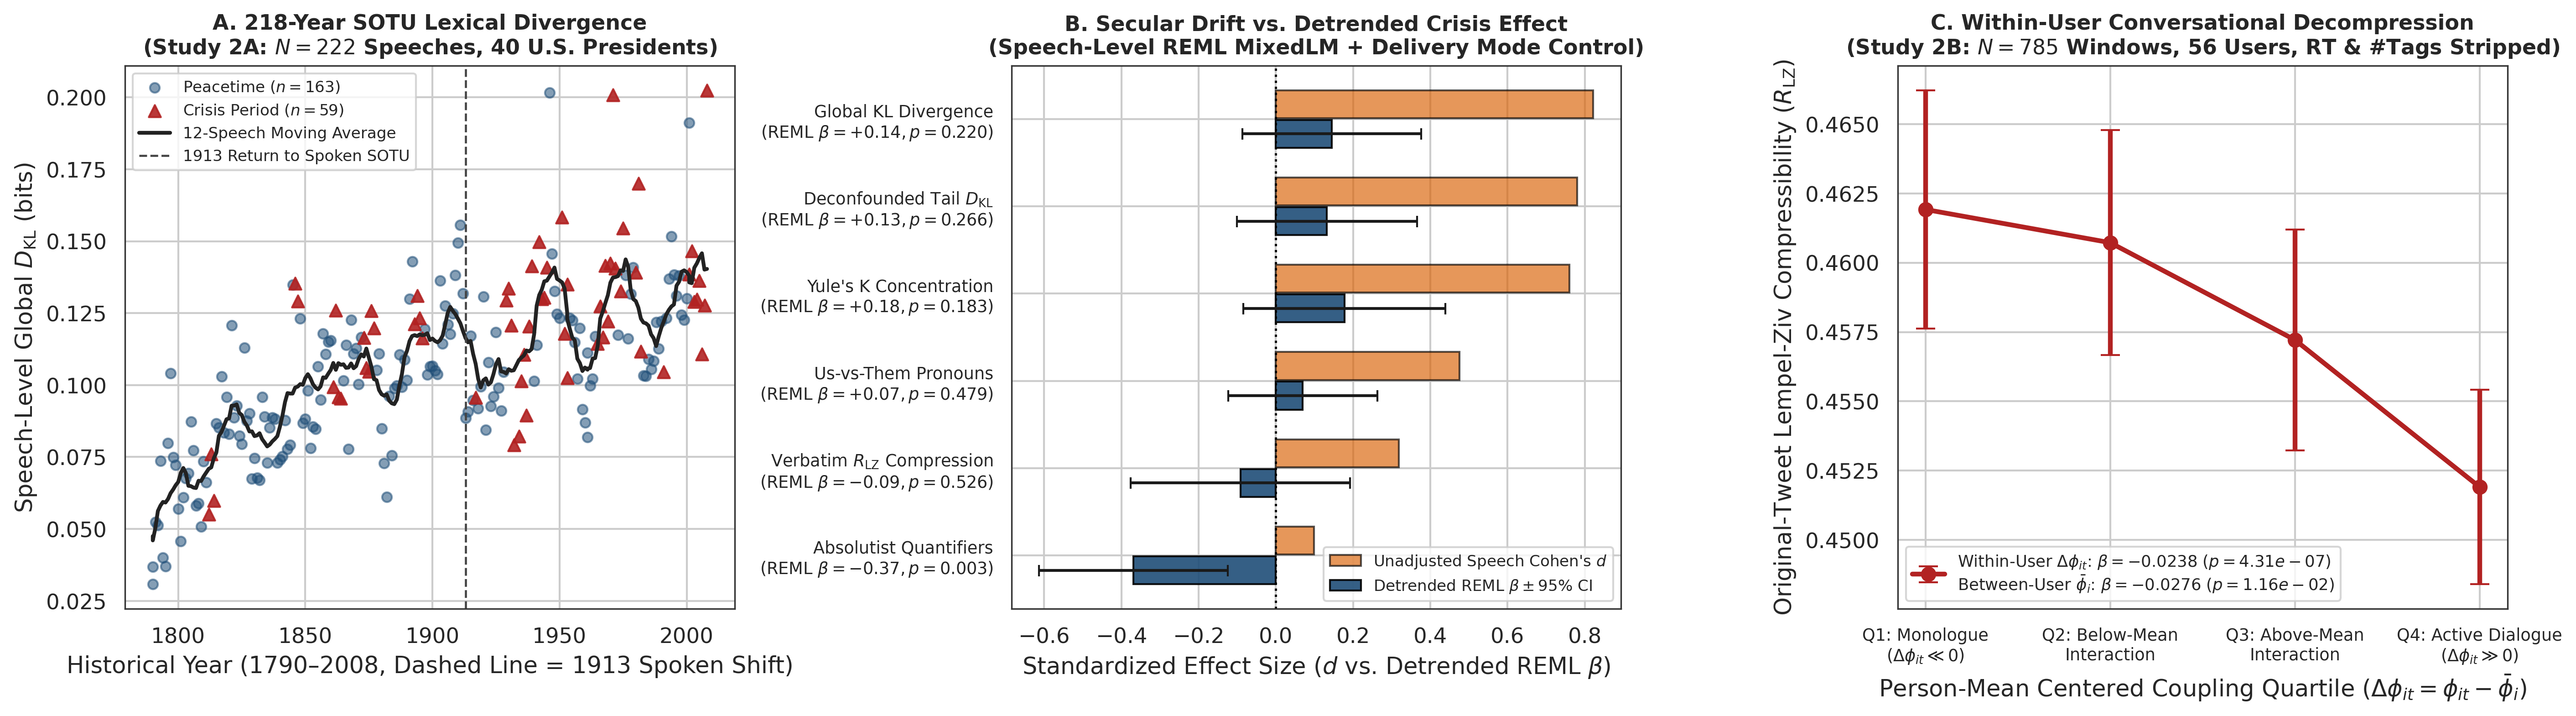

PIPELINE COMPLETE! VERIFYING EXPORTED DATA MATRICES & FIGURES:

Contents of ./data/:
  - study1a_allsides_balanced_w52.csv                  (3,142.4 KB)
  - study1b_single_posts_w40.csv                       (897.7 KB)
  - study1c_stormfront_windows_w50.csv                 (194.8 KB)
  - study2a_sotu_speeches_1790_2008.csv                (53.7 KB)
  - study2b_isis_longitudinal_w150_no_hashtags.csv     (208.1 KB)
  - study2b_sampling_audit_w100.csv                    (113.5 KB)

Contents of ./figures/:
  - Figure_1_RateDistortion_CrossSectional.pdf         (51.1 KB)
  - Figure_1_RateDistortion_CrossSectional.png         (632.3 KB)
  - Figure_2_Historical_And_Network_MixedLM.pdf        (57.3 KB)
  - Figure_2_Historical_And_Network_MixedLM.png        (807.2 KB)


In [7]:
# ==============================================================================
# CELL 7: DYNAMIC FIGURE 2 GENERATOR & FINAL REPOSITORY VERIFICATION MANIFEST
# Outputs: ./figures/Figure_2_Historical_And_Network_MixedLM.pdf & .png
# ==============================================================================
fig2, axes2 = plt.subplots(1, 3, figsize=(19.0, 5.4), dpi=300)

# --- Panel 2A: 218-Year SOTU Trajectory (1790-2008, N=222 Speeches, 40 Presidents) ---
df_sp_sorted = df_sp_agg.sort_values("Year")
peace_sp = df_sp_sorted[df_sp_sorted["Crisis"] == 0]
crisis_sp = df_sp_sorted[df_sp_sorted["Crisis"] == 1]
n_pres = df_sp_agg["President"].nunique()
min_yr, max_yr = int(df_sp_agg["Year"].min()), int(df_sp_agg["Year"].max())

axes2[0].scatter(peace_sp["Year"], peace_sp["D_KL_Global"], color="#1f4e78", alpha=0.55, s=26, label=f"Peacetime ($n={len(peace_sp)}$)")
axes2[0].scatter(crisis_sp["Year"], crisis_sp["D_KL_Global"], color="#b22222", alpha=0.9, s=40, marker="^", label=f"Crisis Period ($n={len(crisis_sp)}$)")
axes2[0].plot(
    df_sp_sorted["Year"], df_sp_sorted["D_KL_Global"].rolling(12, min_periods=3, center=True).mean(),
    color="#222222", linewidth=2.0, label="12-Speech Moving Average"
)
axes2[0].axvline(1913, color="#444444", linestyle="--", linewidth=1.1, label="1913 Return to Spoken SOTU")
axes2[0].set_title(
    f"A. {max_yr - min_yr}-Year SOTU Lexical Divergence\n(Study 2A: $N={len(df_sp_agg)}$ Speeches, {n_pres} U.S. Presidents)",
    fontweight="bold", fontsize=11.0
)
axes2[0].set_xlabel(f"Historical Year ({min_yr}–{max_yr}, Dashed Line = 1913 Spoken Shift)")
axes2[0].set_ylabel(r"Speech-Level Global $D_{\mathrm{KL}}$ (bits)")
axes2[0].legend(loc="upper left", fontsize=8.2, frameon=True)

# --- Panel 2B: Unadjusted Cohen's d vs Detrended Speech-Level REML MixedLM Beta ---
sotu_plot_specs = [
    ("D_KL_Global", "Global KL Divergence"),
    ("D_KL_Tail", "Deconfounded Tail $D_{\\mathrm{KL}}$"),
    ("Yules_K", "Yule's K Concentration"),
    ("UsThem_Pronoun_Density", "Us-vs-Them Pronouns"),
    ("R_LZ_Content", "Verbatim $R_{\\mathrm{LZ}}$ Compression"),
    ("Absolutist_Density", "Absolutist Quantifiers")
]
y_sotu = np.arange(len(sotu_plot_specs))
raw_ds = [sotu_stats_cache[c][0] for c, _ in sotu_plot_specs]
reml_betas = [sotu_stats_cache[c][1] for c, _ in sotu_plot_specs]
reml_ses = [sotu_stats_cache[c][2] for c, _ in sotu_plot_specs]
reml_ps = [sotu_stats_cache[c][3] for c, _ in sotu_plot_specs]
sotu_ylabels = [
    f"{lbl}\n(REML $\\beta={b:+.2f}, p={p:.3f}$)"
    for (_, lbl), b, p in zip(sotu_plot_specs, reml_betas, reml_ps)
]

axes2[1].axvline(0, color="black", linestyle=":", linewidth=1.2)
axes2[1].barh(y_sotu - 0.17, raw_ds, height=0.32, color="#d95f02", alpha=0.65, edgecolor="black", label="Unadjusted Speech Cohen's $d$")
axes2[1].barh(y_sotu + 0.17, reml_betas, xerr=1.96 * np.array(reml_ses), height=0.32, color="#1f4e78", alpha=0.90, capsize=3, edgecolor="black", label="Detrended REML $\\beta \\pm 95\\%$ CI")
axes2[1].set_yticks(y_sotu)
axes2[1].set_yticklabels(sotu_ylabels, fontsize=8.8)
axes2[1].invert_yaxis()
axes2[1].set_title(
    "B. Secular Drift vs. Detrended Crisis Effect\n(Speech-Level REML MixedLM + Delivery Mode Control)",
    fontweight="bold", fontsize=11.0
)
axes2[1].set_xlabel("Standardized Effect Size ($d$ vs. Detrended REML $\\beta$)")
axes2[1].legend(loc="lower right", fontsize=8.2, frameon=True)

# --- Panel 2C: Hashtag- & Retweet-Stripped Monotonic Within-User Decompression ---
q_Order = [
    "Q1: Low Within-User Coupling",
    "Q2: Below-Mean Coupling",
    "Q3: Above-Mean Coupling",
    "Q4: High Within-User Dialogue"
]
q_stats = df_nh.groupby("Phi_Quartile", observed=False)["R_LZ_Content"].agg(["mean", "sem"]).reindex(q_Order)
x_q = np.arange(len(q_Order))
beta_w = md_nh.params["Within_User_Phi_Dev"]
p_w = md_nh.pvalues["Within_User_Phi_Dev"]
beta_b = md_nh.params["User_Mean_Phi"]
p_b = md_nh.pvalues["User_Mean_Phi"]

axes2[2].errorbar(
    x_q, q_stats["mean"], yerr=1.96 * q_stats["sem"],
    fmt="-o", color="#b22222", linewidth=2.5, markersize=7, capsize=5,
    label=f"Within-User $\\Delta\\phi_{{it}}$: $\\beta={beta_w:+.4f}$ ($p={p_w:.2e}$)\nBetween-User $\\bar{{\\phi}}_i$: $\\beta={beta_b:+.4f}$ ($p={p_b:.2e}$)"
)
axes2[2].set_xticks(x_q)
axes2[2].set_xticklabels(["Q1: Monologue\n($\\Delta\\phi_{it} \\ll 0$)", "Q2: Below-Mean\nInteraction", "Q3: Above-Mean\nInteraction", "Q4: Active Dialogue\n($\\Delta\\phi_{it} \\gg 0$)"], fontsize=8.8)
axes2[2].set_title(
    f"C. Within-User Conversational Decompression\n(Study 2B: $N={len(df_nh)}$ Windows, {df_nh['User'].nunique()} Users, RT & #Tags Stripped)",
    fontweight="bold", fontsize=11.0
)
axes2[2].set_xlabel(r"Person-Mean Centered Coupling Quartile ($\Delta\phi_{it} = \phi_{it} - \bar{\phi}_i$)")
axes2[2].set_ylabel(r"Original-Tweet Lempel-Ziv Compressibility ($R_{\mathrm{LZ}}$)")
axes2[2].legend(loc="lower left", fontsize=8.5, frameon=True)

plt.tight_layout()
fig2.savefig("figures/Figure_2_Historical_And_Network_MixedLM.pdf", bbox_inches="tight")
fig2.savefig("figures/Figure_2_Historical_And_Network_MixedLM.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Final Verification Manifest of Exported Files ---
print("="*85)
print("PIPELINE COMPLETE! VERIFYING EXPORTED DATA MATRICES & FIGURES:")
print("="*85)
for folder in ["data", "figures"]:
    print(f"\nContents of ./{folder}/:")
    for fn in sorted(os.listdir(folder)):
        fpath = os.path.join(folder, fn)
        size_kb = os.path.getsize(fpath) / 1024.0
        print(f"  - {fn:<50} ({size_kb:,.1f} KB)")